# Assignment 08 - Part 1: Keras Two-Layer Neural Network on MNIST
**Course:** ECE 5831 - Pattern Recognition and Neural Networks  
**Author:** Michel Temgoua  

## Overview
This notebook implements a Two-Layer Neural Network (`TwoLayerKeras`) using TensorFlow/Keras. It loads the MNIST handwritten digit dataset, trains a multi-layer network with ReLU and Softmax activations, evaluates performance, and visualizes validation and testing results.
We start by loading the MNIST dataset and flattens each $28 \times 28$ image into a 784-dimensional vector, scaling pixel values between $0$ and $1$ for numerical stability.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist

# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()
print("Original data shapes:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

# Flatten and normalize pixel intensity values to [0.0, 1.0]
X_train = X_train.reshape(60000, 28*28).astype("float32") / 255.0
X_test = X_test.reshape(10000, 28*28).astype("float32") / 255.0

print("\nProcessed data shapes:")
print("X_train normalized & flattened:", X_train.shape)
print("X_test normalized & flattened :", X_test.shape)

Original data shapes:
X_train: (60000, 28, 28)
y_train: (60000,)
X_test : (10000, 28, 28)
y_test : (10000,)

Processed data shapes:
X_train normalized & flattened: (60000, 784)
X_test normalized & flattened : (10000, 784)


## TwoLayerKeras Model Definition & Training
We construct a sequential model containing two dense hidden layers with **ReLU** activations and an output layer with **Softmax** activation for 10-class digit classification; Also, it compiles the model using sparse_categorical_crossentropy and trains it for 10 epochs using mini-batch gradient descent (batch_size=64) with a 20% validation split.

In [8]:
class TwoLayerKeras:
    def __init__(self, input_size=784, hidden_size=100, output_size=10):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.model = None

    def create_nn(self):
        self.model = keras.Sequential([
            # Hidden Layer 1
            layers.Dense(self.hidden_size, activation="relu", input_shape=(self.input_size,)),
            # Hidden Layer 2
            layers.Dense(self.hidden_size, activation="relu"),
            # Output Layer
            layers.Dense(self.output_size, activation="softmax")
        ])
        
        self.model.compile(
            optimizer="rmsprop", 
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )
        print(self.model.summary())

# Instantiate and train model
NN = TwoLayerKeras()
NN.create_nn()

history = NN.model.fit(
    X_train, y_train, 
    epochs=10, 
    batch_size=64, 
    validation_split=0.2
)

# Evaluate on test set
predictions = NN.model.predict(X_test)
pred_class = np.argmax(predictions, axis=1)
test_acc = np.mean(y_test == pred_class)
print(f"\nFinal Test Accuracy: {test_acc:.4f}")

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,610 (350.04 KB)

 Trainable params: 89,610 (350.04 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9124 - loss: 0.3049 - val_accuracy: 0.9476 - val_loss: 0.1726
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9603 - loss: 0.1333 - val_accuracy: 0.9597 - val_loss: 0.1346
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9720 - loss: 0.0914 - val_accuracy: 0.9712 - val_loss: 0.0994
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9796 - loss: 0.0682 - val_accuracy: 0.9729 - val_loss: 0.0956
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9828 - loss: 0.0557 - val_accuracy: 0.9719 - val_loss: 0.1012
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9860 - loss: 0.0450 - val_accuracy: 0.9739 - val_loss: 0.0987
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9880 - loss: 0.0377 - val_accuracy: 0.9736 - val_loss: 0.1014
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9897 - loss: 0.0312 - val_accurac

## Plots accuracy trends across epochs to verify convergence and check for overfitting.

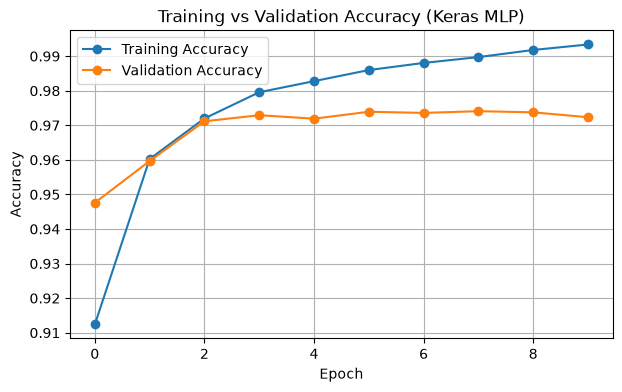

In [9]:
# Plot training vs validation accuracy curves
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy (Keras MLP)")
plt.legend()
plt.grid(True)
plt.show()